# FMA catalogue growth: medium to Large

This notebook reads the paired GPU benchmark output, formats its accuracy and open-set results, and builds a report-ready scaling figure. It does not load CuPy or run inference. The benchmark JSON is the source of truth.

To regenerate the measurements, finish the Large catalogue build and run `python scripts/benchmark_catalogue_growth.py` from the repository root in the CUDA CuPy environment. Then run this notebook in any Python environment with Matplotlib and IPython installed.

## Context and method

Both catalogues are evaluated on identical held-out medium queries, with the same MuQ model, projection head, accuracy-first LSH settings, fixed IVF settings, and frozen open-set thresholds. The Large archive must contain byte-matched medium fingerprints. Search latency measures resident-GPU lookup with synchronization; it excludes extraction, query transfer, index build, and the analysis-only LSH score-gap pass.

The benchmark script loads exact, LSH, and IVF implementations from pinned Git blobs. See [`reports/catalogue-growth-reproduction.md`](../reports/catalogue-growth-reproduction.md) for input construction and reproduction details.

## Load and check the benchmark output

The JSON and Markdown are written by the GPU benchmark. The notebook checks the expected fields before rendering any summaries.

In [1]:
import json
from pathlib import Path

from IPython.display import Markdown, display
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / 'reports' / 'catalogue-growth.json').is_file():
    ROOT = ROOT.parent
RESULT_PATH = ROOT / 'reports' / 'catalogue-growth.json'
if not RESULT_PATH.is_file():
    raise FileNotFoundError(
        f'Missing {RESULT_PATH}. First run scripts/benchmark_catalogue_growth.py after the Large catalogue is complete.'
    )
with RESULT_PATH.open(encoding='utf-8') as handle:
    result = json.load(handle)
for required in ('medium', 'large', 'protocol', 'speed_comparison'):
    if required not in result:
        raise ValueError(f'Benchmark output is missing {required!r}: {RESULT_PATH}')
print(f"GPU benchmark generated {result['generated_utc']} on {result['gpu']}")
print(f'Source: {RESULT_PATH.relative_to(ROOT)}')
pair_check = result['protocol']['medium_large_pair_validation']
print(
    f"Pair check: {pair_check['medium_windows_found_in_large']:,} unchanged Medium windows; "
    f"{pair_check['added_distinct_track_ids']:,} added track IDs; max segment_idx={pair_check['large_max_segment_idx']}; "
    f"long-segment tracks={pair_check['large_tracks_with_segment_idx_above_4']}"
)

GPU benchmark generated 2026-11-23T00:54:28Z on NVIDIA GeForce RTX 4090
Source: reports\catalogue-growth.json
Pair check: 110,320 unchanged Medium windows; 80,735 added track IDs; max segment_idx=121; long-segment tracks=['008747', '008748', '008749', '008750', '008751', '008752', '008753', '008754', '008755', '008756', '008757', '008758', '035724', '036728', '039179', '106611', '106613', '137686']


## Results tables

Closed-set rows retain the original standard and TikTok-like held-out query families. Open-set metrics use the frozen test cohort and unchanged thresholds; the LSH margin uses the top two distinct songs in its exact-scored multprobe candidate union.

In [2]:
def markdown_table(headers, rows):
    header = '| ' + ' | '.join(headers) + ' |'
    separator = '| ' + ' | '.join('---' for _ in headers) + ' |'
    body = ['| ' + ' | '.join(str(value) for value in row) + ' |' for row in rows]
    return '\n'.join([header, separator, *body])

closed_rows = []
for catalogue in ('medium', 'large'):
    for family in ('standard', 'tiktok'):
        methods = result[catalogue]['methods'][family]
        closed_rows.append([
            catalogue.title(), family,
            *[f"{methods[name]['correct']:,}/{methods[name]['queries']:,} ({methods[name]['accuracy']:.2%})"
              for name in ('exact', 'lsh', 'ivf')],
        ])
display(Markdown(markdown_table(
    ['Catalogue', 'Query family', 'Exact', 'Accuracy-first LSH', 'Spherical IVF'],
    closed_rows,
)))

speed_rows = []
for catalogue in ('medium', 'large'):
    exact_ms = result[catalogue]['paired_timing']['exact']['median_ms']
    for method in ('exact', 'lsh', 'ivf'):
        timing = result[catalogue]['paired_timing'][method]
        speedup = exact_ms / timing['median_ms']
        speed_rows.append([
            catalogue.title(), method.upper(), f"{timing['median_ms']:.4f}",
            f"{timing['p95_ms']:.4f}", f"{speedup:.2f}×",
            f"{result[catalogue]['batch_throughput'][method]['queries_per_second']:,.0f}",
        ])
display(Markdown(markdown_table(
    ['Catalogue', 'Method', 'Median ms', 'p95 ms', 'Median speedup vs exact', 'Batch queries/s'],
    speed_rows,
)))
growth_rows = []
for method, values in result['speed_comparison']['large_vs_medium_change'].items():
    growth_rows.append([
        method.upper(), f"{values['median_latency_percent']:+.1f}%",
        f"{values['p95_latency_percent']:+.1f}%",
        f"{values['batch_throughput_percent']:+.1f}%",
    ])
display(Markdown(markdown_table(
    ['Method', 'Median latency change, Large vs Medium', 'p95 latency change, Large vs Medium', 'Batch throughput change, Large vs Medium'],
    growth_rows,
)))

| Catalogue | Query family | Exact | Accuracy-first LSH | Spherical IVF |
| --- | --- | --- | --- | --- |
| Medium | standard | 7,315/7,458 (98.08%) | 7,315/7,458 (98.08%) | 7,274/7,458 (97.53%) |
| Medium | tiktok | 8,411/8,992 (93.54%) | 8,411/8,992 (93.54%) | 8,342/8,992 (92.77%) |
| Large | standard | 7,185/7,458 (96.34%) | 7,195/7,458 (96.47%) | 7,159/7,458 (95.99%) |
| Large | tiktok | 8,095/8,992 (90.02%) | 8,111/8,992 (90.20%) | 8,044/8,992 (89.46%) |

| Catalogue | Method | Median ms | p95 ms | Median speedup vs exact | Batch queries/s |
| --- | --- | --- | --- | --- | --- |
| Medium | EXACT | 0.1730 | 0.1976 | 1.00× | 376,036 |
| Medium | LSH | 0.0815 | 0.0979 | 2.12× | 71,854 |
| Medium | IVF | 0.0699 | 0.0805 | 2.47× | 433,447 |
| Large | EXACT | 0.5849 | 0.6672 | 1.00× | 95,267 |
| Large | LSH | 0.2533 | 0.3326 | 2.31× | 7,057 |
| Large | IVF | 0.1238 | 0.2392 | 4.72× | 89,420 |

| Method | Median latency change, Large vs Medium | p95 latency change, Large vs Medium | Batch throughput change, Large vs Medium |
| --- | --- | --- | --- |
| EXACT | +238.1% | +237.6% | -74.7% |
| LSH | +210.8% | +239.6% | -90.2% |
| IVF | +77.2% | +197.1% | -79.4% |

### Fixed-threshold open-set evaluation

All designated missing-song IDs are removed from both catalogues before scoring. Thresholds were selected on the development split and are transferred unchanged here. The LSH top-two score-gap is computed only over its frozen bucket union and is not included in lookup timing.

In [3]:
open_rows = []
for catalogue in ('medium', 'large'):
    for method in ('exact', 'ivf', 'lsh'):
        for rule, metrics in result[catalogue]['open_set'][method].items():
            if 'known_correct' not in metrics:
                continue
            open_rows.append([
                catalogue.title(), method.upper(), rule.replace('_', ' '),
                f"{metrics['known_correct']:,}/{metrics['known_queries']:,} ({metrics['known_correct_rate']:.2%})",
                f"{metrics['unknown_false_accepts']:,}/{metrics['unknown_queries']:,} ({metrics['unknown_false_acceptance_rate']:.2%})",
            ])
display(Markdown(markdown_table(
    ['Catalogue', 'Method', 'Frozen rule', 'Known correct accepted', 'Unknown false accepts'],
    open_rows,
)))

family_rows = []
for catalogue in ('medium', 'large'):
    for method in ('exact', 'ivf', 'lsh'):
        for rule, metrics in result[catalogue]['open_set'][method].items():
            if 'known_correct' not in metrics:
                continue
            for family, values in metrics['by_family'].items():
                known_rate = values['known_correct_rate']
                unknown_rate = values['unknown_false_acceptance_rate']
                family_rows.append([
                    catalogue.title(), method.upper(), rule.replace('_', ' '), family,
                    'n/a' if known_rate is None else f'{known_rate:.2%}',
                    'n/a' if unknown_rate is None else f'{unknown_rate:.2%}',
                ])
display(Markdown(markdown_table(
    ['Catalogue', 'Method', 'Frozen rule', 'Family', 'Known correct rate', 'Unknown false-accept rate'],
    family_rows,
)))
tie_audit = result['medium']['open_set'].get('pr6_score_only_tie_reconciliation')
if tie_audit:
    display(Markdown(
        f"PR6 score-only count: {tie_audit['pr6_known_correct_score_only_accepts']}/1024; "
        f"strict CuPy row-order top-1: {tie_audit['cupy_strict_known_correct_score_only_accepts']}/1024; "
        f"tie-aware: {tie_audit['tie_aware_known_correct_score_only_accepts']}/1024. "
        + tie_audit['interpretation']
    ))
    tie_rows = [[
        tie['test_query_index'], tie['family'], tie['distortion'], tie['track_id'],
        tie['cupy_winner'], f"{tie['pr6_winner_score']:.9f}",
        f"+{tie['winner_score_minus_threshold']:.9f}",
    ] for tie in tie_audit['tie_cases']]
    display(Markdown(markdown_table(
        ['Test query', 'Family', 'Distortion', 'Known track', 'CuPy winner', 'Tied cosine', 'Score minus threshold'],
        tie_rows,
    )))

| Catalogue | Method | Frozen rule | Known correct accepted | Unknown false accepts |
| --- | --- | --- | --- | --- |
| Medium | EXACT | frozen maximum score | 536/1,024 (52.34%) | 4/1,024 (0.39%) |
| Medium | EXACT | frozen score and gap | 731/1,024 (71.39%) | 11/1,024 (1.07%) |
| Medium | IVF | frozen maximum score | 536/1,024 (52.34%) | 4/1,024 (0.39%) |
| Medium | IVF | frozen score and gap | 725/1,024 (70.80%) | 11/1,024 (1.07%) |
| Medium | LSH | frozen maximum score | 536/1,024 (52.34%) | 4/1,024 (0.39%) |
| Medium | LSH | frozen score and gap | 731/1,024 (71.39%) | 11/1,024 (1.07%) |
| Large | EXACT | frozen maximum score | 523/1,024 (51.07%) | 18/1,024 (1.76%) |
| Large | EXACT | frozen score and gap | 691/1,024 (67.48%) | 23/1,024 (2.25%) |
| Large | IVF | frozen maximum score | 523/1,024 (51.07%) | 18/1,024 (1.76%) |
| Large | IVF | frozen score and gap | 684/1,024 (66.80%) | 23/1,024 (2.25%) |
| Large | LSH | frozen maximum score | 526/1,024 (51.37%) | 18/1,024 (1.76%) |
| Large | LSH | frozen score and gap | 691/1,024 (67.48%) | 23/1,024 (2.25%) |

| Catalogue | Method | Frozen rule | Family | Known correct rate | Unknown false-accept rate |
| --- | --- | --- | --- | --- | --- |
| Medium | EXACT | frozen maximum score | standard | 71.68% | 0.78% |
| Medium | EXACT | frozen maximum score | tiktok | 33.01% | 0.00% |
| Medium | EXACT | frozen score and gap | standard | 88.67% | 1.56% |
| Medium | EXACT | frozen score and gap | tiktok | 54.10% | 0.59% |
| Medium | IVF | frozen maximum score | standard | 71.68% | 0.78% |
| Medium | IVF | frozen maximum score | tiktok | 33.01% | 0.00% |
| Medium | IVF | frozen score and gap | standard | 88.28% | 1.56% |
| Medium | IVF | frozen score and gap | tiktok | 53.32% | 0.59% |
| Medium | LSH | frozen maximum score | standard | 71.68% | 0.78% |
| Medium | LSH | frozen maximum score | tiktok | 33.01% | 0.00% |
| Medium | LSH | frozen score and gap | standard | 88.67% | 1.56% |
| Medium | LSH | frozen score and gap | tiktok | 54.10% | 0.59% |
| Large | EXACT | frozen maximum score | standard | 70.51% | 2.73% |
| Large | EXACT | frozen maximum score | tiktok | 31.64% | 0.78% |
| Large | EXACT | frozen score and gap | standard | 83.98% | 3.12% |
| Large | EXACT | frozen score and gap | tiktok | 50.98% | 1.37% |
| Large | IVF | frozen maximum score | standard | 70.31% | 2.73% |
| Large | IVF | frozen maximum score | tiktok | 31.84% | 0.78% |
| Large | IVF | frozen score and gap | standard | 83.20% | 3.12% |
| Large | IVF | frozen score and gap | tiktok | 50.39% | 1.37% |
| Large | LSH | frozen maximum score | standard | 70.90% | 2.73% |
| Large | LSH | frozen maximum score | tiktok | 31.84% | 0.78% |
| Large | LSH | frozen score and gap | standard | 83.98% | 3.12% |
| Large | LSH | frozen score and gap | tiktok | 50.98% | 1.37% |

PR6 score-only count: 538/1024; strict CuPy row-order top-1: 536/1024; tie-aware: 538/1024. PR6 uses PyTorch top-k tie selection; the pinned CuPy exact search picks the first matching reference row. The tied scores and frozen threshold are unchanged, but deterministic top-1 tie winners differ.

| Test query | Family | Distortion | Known track | CuPy winner | Tied cosine | Score minus threshold |
| --- | --- | --- | --- | --- | --- | --- |
| 16 | standard | time_stretch | 117253 | 117089 | 0.887678623 | +0.053468704 |
| 960 | standard | high_pass | 122153 | 046066 | 0.893376529 | +0.059166610 |

## Accuracy and lookup scaling

Median lookup latency is shown with a one-sided whisker to the measured p95. Accuracy is shown for both held-out query families and all three methods; its focused 88–100% axis makes catalogue-related losses visible. The catalogue axis uses the exact reference-window count from the benchmark. The table reports median, p95, and batch throughput changes from Medium to Large.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


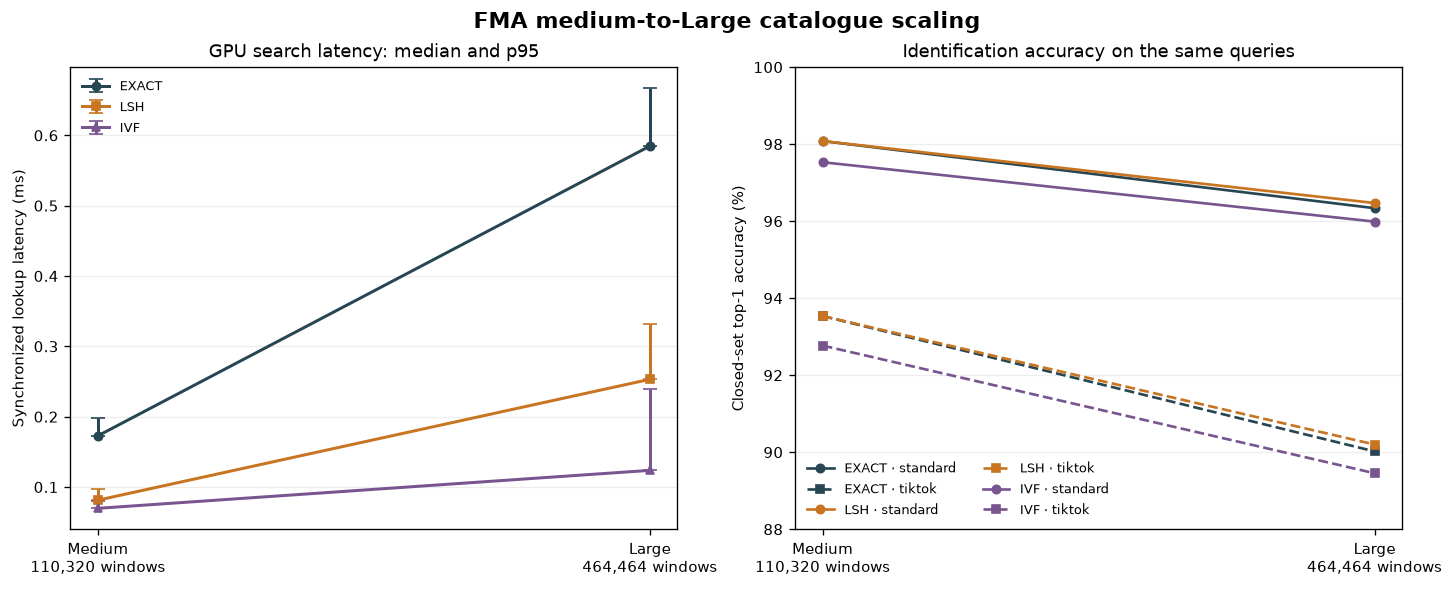

Report figures saved to reports\catalogue-growth.png and reports\catalogue-growth.pdf


In [4]:
plt.rcParams.update({
    'font.size': 9,
    'axes.titlesize': 11,
    'axes.labelsize': 9,
    'legend.fontsize': 8,
    'figure.dpi': 120,
})
palette = {'exact': '#264653', 'lsh': '#C87522', 'ivf': '#78558F'}
markers = {'exact': 'o', 'lsh': 's', 'ivf': '^'}
catalogues = ('medium', 'large')
x = [0, 1]
xlabels = [
    f"Medium\n{result['medium']['reference_windows']:,} windows",
    f"Large\n{result['large']['reference_windows']:,} windows",
]
fig, (latency_ax, accuracy_ax) = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)

for method in ('exact', 'lsh', 'ivf'):
    medians = [result[name]['paired_timing'][method]['median_ms'] for name in catalogues]
    p95s = [result[name]['paired_timing'][method]['p95_ms'] for name in catalogues]
    upper = [max(0, p95 - median) for p95, median in zip(p95s, medians)]
    latency_ax.errorbar(
        x, medians, yerr=[[0, 0], upper], marker=markers[method],
        color=palette[method], linewidth=1.8, markersize=5, capsize=4,
        label=method.upper(),
    )
latency_ax.set_xticks(x, xlabels)
latency_ax.set_ylabel('Synchronized lookup latency (ms)')
latency_ax.set_title('GPU search latency: median and p95')
latency_ax.grid(axis='y', alpha=0.22)
latency_ax.legend(frameon=False)

family_styles = {'standard': ('o', '-'), 'tiktok': ('s', '--')}
for method in ('exact', 'lsh', 'ivf'):
    for family in ('standard', 'tiktok'):
        marker, linestyle = family_styles[family]
        accuracies = [
            result[name]['methods'][family][method]['accuracy'] * 100
            for name in catalogues
        ]
        accuracy_ax.plot(
            x, accuracies, marker=marker, linestyle=linestyle,
            color=palette[method], linewidth=1.6, markersize=5,
            label=f'{method.upper()} · {family}',
        )
accuracy_ax.set_xticks(x, xlabels)
accuracy_ax.set_ylabel('Closed-set top-1 accuracy (%)')
accuracy_ax.set_ylim(88, 100)
accuracy_ax.set_title('Identification accuracy on the same queries')
accuracy_ax.grid(axis='y', alpha=0.22)
accuracy_ax.legend(frameon=False, ncol=2, loc='lower left')

fig.suptitle('FMA medium-to-Large catalogue scaling', fontsize=13, fontweight='semibold')
figure_path = ROOT / 'reports' / 'catalogue-growth.png'
figure_pdf_path = ROOT / 'reports' / 'catalogue-growth.pdf'
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=240, bbox_inches='tight')
fig.savefig(figure_pdf_path, bbox_inches='tight')
plt.show()
print(f'Report figures saved to {figure_path.relative_to(ROOT)} and {figure_pdf_path.relative_to(ROOT)}')

## Paired changes and nested-catalogue checks

The exact results have useful monotonicity checks: with identical medium rows and only distinct new song IDs added, exact search should not turn a medium error into a correct answer; max-score unknown false accepts should not decline at a fixed threshold; and a new competitor cannot increase a known-correct winner's score gap. Any violation is recorded alongside query-level score diagnostics for review.

In [5]:
change_rows = []
changes = result['large']['paired_changes_vs_medium']
for family in ('standard', 'tiktok'):
    for method, values in changes[family].items():
        change_rows.append([
            family, method.upper(), values['lost_correct'], values['gained_correct'],
            f"{values['accuracy_change_percentage_points']:+.3f}",
        ])
display(Markdown(markdown_table(
    ['Family', 'Method', 'Lost correct', 'Gained correct', 'Accuracy change (pp)'],
    change_rows,
)))

checks = result['large']['exact_search_nested_catalogue_checks']
display(Markdown('**Exact nested-catalogue checks**\n\n' + json.dumps(checks, indent=2)))

| Family | Method | Lost correct | Gained correct | Accuracy change (pp) |
| --- | --- | --- | --- | --- |
| standard | EXACT | 130 | 0 | -1.743 |
| standard | LSH | 120 | 0 | -1.609 |
| standard | IVF | 141 | 26 | -1.542 |
| tiktok | EXACT | 316 | 0 | -3.514 |
| tiktok | LSH | 300 | 0 | -3.336 |
| tiktok | IVF | 348 | 50 | -3.314 |

**Exact nested-catalogue checks**

{
  "closed_set_exact_correct_gains": {
    "standard": 0,
    "tiktok": 0
  },
  "open_set": {
    "score_only_unknown_false_accepts": {
      "medium": 4,
      "large": 18,
      "non_decreasing": true,
      "no_medium_accept_became_large_reject": true,
      "unexpected_declines": []
    },
    "score_plus_gap_known_correct_accepts": {
      "medium": 731,
      "large": 691,
      "non_increasing": true,
      "no_new_correct_accepts": true,
      "unexpected_new_accepts": []
    }
  },
  "closed_set_exact_gain_score_diagnostics": {
    "standard": {
      "gained_correct_queries": 0,
      "score_diagnostics": []
    },
    "tiktok": {
      "gained_correct_queries": 0,
      "score_diagnostics": []
    }
  },
  "interpretation": "Adding distinct tracks cannot mathematically turn an exact medium error into a correct match. If a recorded gain appears, inspect score ties and GPU floating-point changes."
}

## Takeaways

Use the executed tables and plotted values above to describe the accuracy and speed tradeoff. The fixed thresholds make the open-set comparison a transfer test: changes reflect catalogue scale under the old operating point, not a newly optimized threshold. The LSH score-gap result is an analysis of candidate competition, while the LSH timing remains the pinned production lookup.